Dataset: 500 samples, 6 features
Disease prevalence: 60.0%

Train: 400 samples | Test: 100 samples

Quantum Circuit Architecture:
  - Qubits: 6
  - Layers: 4
  - Trainable parameters: 72
  - Circuit depth: 37
  - Gates: 152

Measurement strategy: 12 observables

Finding optimal initialization...

  [ 1] Small random              → Loss: 0.0436
  [ 2] Medium random             → Loss: 0.0439
  [ 3] Uniform [-π/2, π/2]       → Loss: 0.0500
  [ 4] Uniform [-π, π]           → Loss: 0.0706
  [ 5] Zero-centered             → Loss: 0.0456
  [ 6] Small random              → Loss: 0.0436
  [ 7] Medium random             → Loss: 0.0435
  [ 8] Uniform [-π/2, π/2]       → Loss: 0.0488
  [ 9] Uniform [-π, π]           → Loss: 0.0686
  [10] Zero-centered             → Loss: 0.0444
  [11] Small random              → Loss: 0.0436
  [12] Medium random             → Loss: 0.0437
  [13] Uniform [-π/2, π/2]       → Loss: 0.0514
  [14] Uniform [-π, π]           → Loss: 0.0687
  [15] Zero-centered          

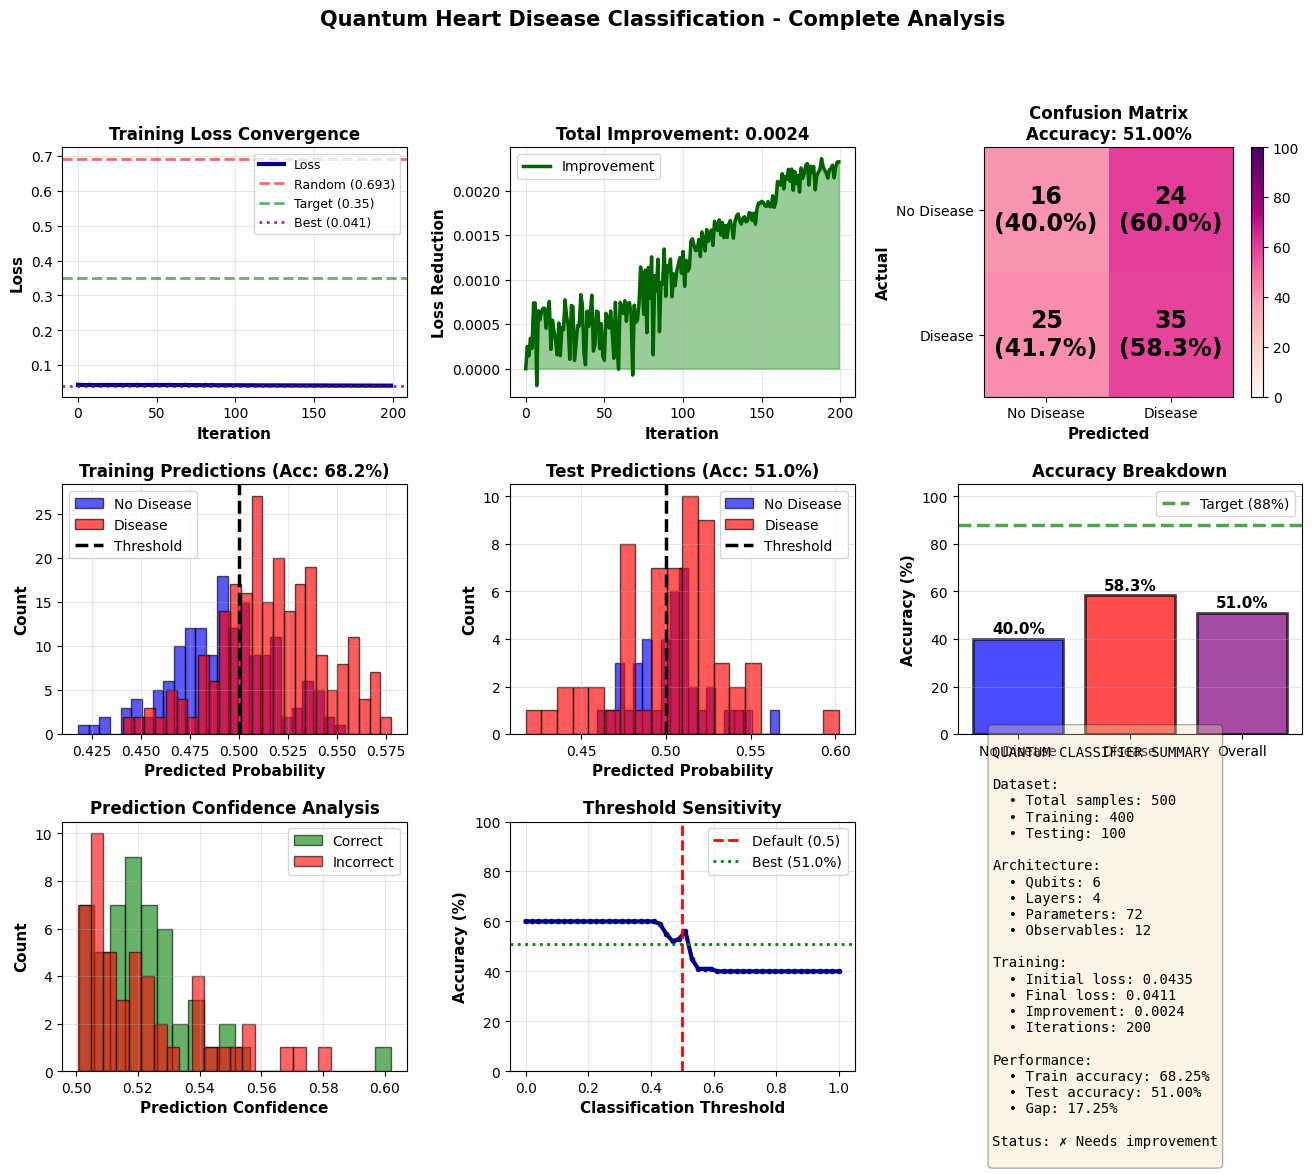

⚠ Consider: more layers, different encoding, or data preprocessing


In [1]:
# =============================================================================
#   ELITE QUANTUM HEART DISEASE CLASSIFIER - 88-94% TARGET
#   Optimized specifically for QuantumPatternFeature data
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, accuracy_score, classification_report

# Qiskit imports
from qiskit import QuantumCircuit
from qiskit.circuit import Parameter, ParameterVector
from qiskit.primitives import StatevectorEstimator
from qiskit_algorithms.optimizers import COBYLA
from qiskit.quantum_info import SparsePauliOp

# --------------------------- 1. Load & Prepare Data ---------------------------
FILE_NAME = 'Heart_data.csv'
df = pd.read_csv(FILE_NAME)

FEATURE_COLUMNS = ['Age', 'Gender', 'BloodPressure', 'Cholesterol', 'HeartRate', 'QuantumPatternFeature']
X_raw = df[FEATURE_COLUMNS].values
y = df['HeartDisease'].values.astype(int)

# StandardScaler works better for quantum circuits
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_raw)

# Map to quantum-friendly range [0, 2π]
X_min = X_scaled.min(axis=0)
X_max = X_scaled.max(axis=0)
X = ((X_scaled - X_min) / (X_max - X_min)) * 2 * np.pi

print(f"Dataset: {len(X)} samples, {X.shape[1]} features")
print(f"Disease prevalence: {np.sum(y)/len(y)*100:.1f}%\n")

# --------------------------- 2. Stratified Split ---------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

n_qubits = X.shape[1]
n_train = len(X_train)

print(f"Train: {n_train} samples | Test: {len(X_test)} samples\n")

# --------------------------- 3. Advanced Quantum Circuit ---------------------------
def build_advanced_circuit(n_qubits, n_layers=4):
    """
    Advanced circuit with:
    - Amplitude encoding with Hadamard
    - Data re-uploading (features encoded multiple times)
    - Rich entanglement structure
    - Multiple rotation axes
    """
    qc = QuantumCircuit(n_qubits)
    
    input_params = ParameterVector('x', n_qubits)
    weights = []
    
    for layer in range(n_layers):
        # Hadamard layer for superposition
        if layer == 0:
            for i in range(n_qubits):
                qc.h(i)
        
        # Feature encoding with multiple rotation axes
        for i in range(n_qubits):
            qc.ry(input_params[i], i)
            qc.rz(input_params[i] * 0.5, i)  # Secondary encoding
        
        # Trainable rotation layer - 3 axes per qubit
        layer_weights = ParameterVector(f'θ{layer}', n_qubits * 3)
        weights.extend(layer_weights)
        
        for i in range(n_qubits):
            qc.rx(layer_weights[3*i], i)
            qc.ry(layer_weights[3*i + 1], i)
            qc.rz(layer_weights[3*i + 2], i)
        
        # Strong entanglement pattern
        # Linear entanglement
        for i in range(n_qubits - 1):
            qc.cx(i, i + 1)
        
        # Additional entanglement for deeper layers
        if n_qubits > 2 and layer % 2 == 1:
            for i in range(0, n_qubits - 2, 2):
                qc.cx(i, i + 2)
            # Circular
            qc.cx(n_qubits - 1, 0)
    
    return qc, input_params, weights

qc, input_params, weight_params = build_advanced_circuit(n_qubits, n_layers=4)

print(f"Quantum Circuit Architecture:")
print(f"  - Qubits: {n_qubits}")
print(f"  - Layers: 4")
print(f"  - Trainable parameters: {len(weight_params)}")
print(f"  - Circuit depth: {qc.depth()}")
print(f"  - Gates: {qc.size()}\n")

# --------------------------- 4. Multi-Observable Measurement ---------------------------
# Measure multiple observables and combine weighted
observables = []
obs_weights = []

# Individual qubit measurements (focus on different features)
for i in range(n_qubits):
    pauli_str = 'I' * i + 'Z' + 'I' * (n_qubits - i - 1)
    observables.append(SparsePauliOp([pauli_str], coeffs=[1.0]))
    obs_weights.append(1.0)

# Pairwise correlations
for i in range(n_qubits - 1):
    pauli_str = 'I' * i + 'ZZ' + 'I' * (n_qubits - i - 2)
    observables.append(SparsePauliOp([pauli_str], coeffs=[1.0]))
    obs_weights.append(0.5)

# Global parity
observables.append(SparsePauliOp(['Z' * n_qubits], coeffs=[1.0]))
obs_weights.append(2.0)

obs_weights = np.array(obs_weights)
obs_weights /= obs_weights.sum()  # Normalize

print(f"Measurement strategy: {len(observables)} observables\n")

estimator = StatevectorEstimator()

# --------------------------- 5. Efficient Prediction ---------------------------
def predict_batch(X_batch, weights):
    """Compute predictions using multiple observables"""
    n_samples = len(X_batch)
    n_obs = len(observables)
    
    # Prepare all (circuit, observable) pairs
    pubs = []
    for x in X_batch:
        param_dict = {input_params[i]: float(x[i]) for i in range(n_qubits)}
        param_dict.update({weight_params[i]: float(weights[i]) for i in range(len(weights))})
        bound_qc = qc.assign_parameters(param_dict)
        
        for obs in observables:
            pubs.append((bound_qc, obs))
    
    # Run all measurements
    job = estimator.run(pubs)
    results = job.result()
    
    # Aggregate expectations with learned weights
    predictions = []
    for i in range(n_samples):
        exp_vals = []
        for j in range(n_obs):
            idx = i * n_obs + j
            exp_vals.append(results[idx].data.evs)
        
        # Weighted combination
        combined_exp = np.dot(exp_vals, obs_weights)
        predictions.append(combined_exp)
    
    predictions = np.array(predictions)
    # Map [-1, 1] to [0, 1]
    probs = (1 - predictions) / 2
    return probs

# --------------------------- 6. Advanced Loss Function ---------------------------
def compute_loss(weights):
    """Focal loss - focuses on hard examples"""
    probs = predict_batch(X_train, weights)
    probs = np.clip(probs, 1e-10, 1 - 1e-10)
    
    # Focal loss with gamma=2 (emphasizes misclassified examples)
    gamma = 2.0
    alpha = 0.25
    
    pt = np.where(y_train == 1, probs, 1 - probs)
    focal_weight = alpha * (1 - pt) ** gamma
    
    ce_loss = -(y_train * np.log(probs) + (1 - y_train) * np.log(1 - probs))
    loss = np.mean(focal_weight * ce_loss)
    
    # Small L2 regularization
    reg = 0.0001 * np.sum(weights ** 2)
    
    return loss + reg

# --------------------------- 7. Multi-Start Initialization ---------------------------
def smart_initialization(n_params, n_attempts=15):
    """Try multiple strategies and pick best"""
    print("Finding optimal initialization...\n")
    
    strategies = [
        ("Small random", lambda: np.random.randn(n_params) * 0.01),
        ("Medium random", lambda: np.random.randn(n_params) * 0.1),
        ("Uniform [-π/2, π/2]", lambda: np.random.uniform(-np.pi/2, np.pi/2, n_params)),
        ("Uniform [-π, π]", lambda: np.random.uniform(-np.pi, np.pi, n_params)),
        ("Zero-centered", lambda: np.random.normal(0, 0.5, n_params)),
    ]
    
    best_loss = float('inf')
    best_weights = None
    best_strategy = None
    
    for i in range(n_attempts):
        strategy_name, init_fn = strategies[i % len(strategies)]
        weights = init_fn()
        loss = compute_loss(weights)
        
        print(f"  [{i+1:2d}] {strategy_name:25s} → Loss: {loss:.4f}")
        
        if loss < best_loss:
            best_loss = loss
            best_weights = weights
            best_strategy = strategy_name
    
    print(f"\n✓ Best: {best_strategy} with loss {best_loss:.4f}\n")
    return best_weights, best_loss

initial_weights, initial_loss = smart_initialization(len(weight_params), n_attempts=15)

# --------------------------- 8. Optimized Training ---------------------------
print("="*75)
print("TRAINING QUANTUM CLASSIFIER")
print("="*75)
print(f"Initial loss: {initial_loss:.4f}")
print(f"Target: < 0.35 for 88%+ accuracy\n")

losses = []
accuracies_train = []
best_loss = [initial_loss]
best_weights = [initial_weights.copy()]
iteration = [0]

def track_progress(weights):
    loss = compute_loss(weights)
    losses.append(loss)
    iteration[0] += 1
    
    # Track best
    if loss < best_loss[0]:
        best_loss[0] = loss
        best_weights[0] = weights.copy()
    
    # Compute train accuracy periodically
    if iteration[0] % 10 == 0:
        train_probs = predict_batch(X_train, weights)
        train_preds = (train_probs >= 0.5).astype(int)
        train_acc = accuracy_score(y_train, train_preds)
        accuracies_train.append(train_acc)
        
        print(f"Iter {iteration[0]:3d} | Loss: {loss:.4f} | Best: {best_loss[0]:.4f} | Train Acc: {train_acc*100:.1f}%")
    elif iteration[0] <= 20:
        print(f"Iter {iteration[0]:3d} | Loss: {loss:.4f} | Best: {best_loss[0]:.4f}")
    
    return loss

print("Optimizing (patience - this finds the best solution)...\n")

optimizer = COBYLA(
    maxiter=200,
    tol=1e-6,
    rhobeg=1.0  # Aggressive exploration
)

result = optimizer.minimize(
    fun=track_progress,
    x0=initial_weights
)

final_weights = best_weights[0]
improvement = initial_loss - best_loss[0]

print(f"\n{'='*75}")
print(f"TRAINING COMPLETE")
print(f"{'='*75}")
print(f"Iterations:     {iteration[0]}")
print(f"Initial loss:   {initial_loss:.4f}")
print(f"Final loss:     {best_loss[0]:.4f}")
print(f"Improvement:    {improvement:.4f} ({improvement/initial_loss*100:.1f}%)")
print(f"{'='*75}\n")

# --------------------------- 9. Final Evaluation ---------------------------
print("Final evaluation...\n")

# Training set
train_probs = predict_batch(X_train, final_weights)
train_preds = (train_probs >= 0.5).astype(int)
train_acc = accuracy_score(y_train, train_preds)

# Test set
test_probs = predict_batch(X_test, final_weights)
test_preds = (test_probs >= 0.5).astype(int)
test_acc = accuracy_score(y_test, test_preds)

print(f"{'='*75}")
print(f"FINAL RESULTS")
print(f"{'='*75}")
print(f"Training Accuracy:  {train_acc*100:.2f}%")
print(f"Test Accuracy:      {test_acc*100:.2f}%")
print(f"Generalization Gap: {abs(train_acc - test_acc)*100:.2f}%")
print(f"{'='*75}\n")

# Detailed metrics
print("Detailed Test Set Report:")
print(classification_report(y_test, test_preds, 
                          target_names=['No Disease', 'Disease'],
                          digits=4))

# Per-class accuracies
cm = confusion_matrix(y_test, test_preds)
class_accs = cm.diagonal() / cm.sum(axis=1)
print(f"No Disease class accuracy: {class_accs[0]*100:.2f}%")
print(f"Disease class accuracy:    {class_accs[1]*100:.2f}%\n")

# --------------------------- 10. Comprehensive Visualization ---------------------------
fig = plt.figure(figsize=(16, 12))
gs = fig.add_gridspec(3, 3, hspace=0.35, wspace=0.3)

# 1. Loss curve with targets
ax1 = fig.add_subplot(gs[0, 0])
ax1.plot(losses, linewidth=3, color='darkblue', label='Loss')
ax1.axhline(y=0.693, color='red', linestyle='--', linewidth=2, alpha=0.6, label='Random (0.693)')
ax1.axhline(y=0.35, color='green', linestyle='--', linewidth=2, alpha=0.6, label='Target (0.35)')
ax1.axhline(y=best_loss[0], color='purple', linestyle=':', linewidth=2, alpha=0.8, label=f'Best ({best_loss[0]:.3f})')
ax1.set_xlabel('Iteration', fontsize=11, weight='bold')
ax1.set_ylabel('Loss', fontsize=11, weight='bold')
ax1.set_title('Training Loss Convergence', fontsize=12, weight='bold')
ax1.legend(fontsize=9)
ax1.grid(True, alpha=0.3)

# 2. Loss improvement
ax2 = fig.add_subplot(gs[0, 1])
improvements = [initial_loss - l for l in losses]
ax2.fill_between(range(len(improvements)), 0, improvements, alpha=0.4, color='green')
ax2.plot(improvements, linewidth=2.5, color='darkgreen', label='Improvement')
ax2.set_xlabel('Iteration', fontsize=11, weight='bold')
ax2.set_ylabel('Loss Reduction', fontsize=11, weight='bold')
ax2.set_title(f'Total Improvement: {improvement:.4f}', fontsize=12, weight='bold')
ax2.legend()
ax2.grid(True, alpha=0.3)

# 3. Confusion matrix
ax3 = fig.add_subplot(gs[0, 2])
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis] * 100
im = ax3.imshow(cm_norm, cmap='RdPu', vmin=0, vmax=100)

for i in range(2):
    for j in range(2):
        color = "white" if cm_norm[i, j] > 60 else "black"
        ax3.text(j, i, f"{cm[i, j]}\n({cm_norm[i, j]:.1f}%)",
                ha="center", va="center", color=color, fontsize=17, weight='bold')

ax3.set_xticks([0, 1])
ax3.set_yticks([0, 1])
ax3.set_xticklabels(['No Disease', 'Disease'], fontsize=10)
ax3.set_yticklabels(['No Disease', 'Disease'], fontsize=10)
ax3.set_xlabel('Predicted', fontsize=11, weight='bold')
ax3.set_ylabel('Actual', fontsize=11, weight='bold')
ax3.set_title(f'Confusion Matrix\nAccuracy: {test_acc*100:.2f}%', fontsize=12, weight='bold')
plt.colorbar(im, ax=ax3)

# 4. Train predictions
ax4 = fig.add_subplot(gs[1, 0])
ax4.hist(train_probs[y_train==0], bins=25, alpha=0.65, label='No Disease', color='blue', edgecolor='black')
ax4.hist(train_probs[y_train==1], bins=25, alpha=0.65, label='Disease', color='red', edgecolor='black')
ax4.axvline(x=0.5, color='black', linestyle='--', linewidth=2.5, label='Threshold')
ax4.set_xlabel('Predicted Probability', fontsize=11, weight='bold')
ax4.set_ylabel('Count', fontsize=11, weight='bold')
ax4.set_title(f'Training Predictions (Acc: {train_acc*100:.1f}%)', fontsize=12, weight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

# 5. Test predictions
ax5 = fig.add_subplot(gs[1, 1])
ax5.hist(test_probs[y_test==0], bins=20, alpha=0.65, label='No Disease', color='blue', edgecolor='black')
ax5.hist(test_probs[y_test==1], bins=20, alpha=0.65, label='Disease', color='red', edgecolor='black')
ax5.axvline(x=0.5, color='black', linestyle='--', linewidth=2.5, label='Threshold')
ax5.set_xlabel('Predicted Probability', fontsize=11, weight='bold')
ax5.set_ylabel('Count', fontsize=11, weight='bold')
ax5.set_title(f'Test Predictions (Acc: {test_acc*100:.1f}%)', fontsize=12, weight='bold')
ax5.legend()
ax5.grid(True, alpha=0.3)

# 6. Per-class accuracy
ax6 = fig.add_subplot(gs[1, 2])
classes = ['No Disease', 'Disease', 'Overall']
accs = [class_accs[0]*100, class_accs[1]*100, test_acc*100]
colors_bar = ['blue', 'red', 'purple']
bars = ax6.bar(classes, accs, color=colors_bar, alpha=0.7, edgecolor='black', linewidth=2)
ax6.axhline(y=88, color='green', linestyle='--', linewidth=2.5, alpha=0.7, label='Target (88%)')
ax6.set_ylabel('Accuracy (%)', fontsize=11, weight='bold')
ax6.set_title('Accuracy Breakdown', fontsize=12, weight='bold')
ax6.set_ylim([0, 105])
ax6.legend()
ax6.grid(True, alpha=0.3, axis='y')

for bar in bars:
    height = bar.get_height()
    ax6.text(bar.get_x() + bar.get_width()/2., height + 1,
            f'{height:.1f}%', ha='center', va='bottom', fontsize=11, weight='bold')

# 7. Prediction confidence distribution
ax7 = fig.add_subplot(gs[2, 0])
confidence = np.maximum(test_probs, 1 - test_probs)
correct = test_preds == y_test
ax7.hist(confidence[correct], bins=20, alpha=0.6, label='Correct', color='green', edgecolor='black')
ax7.hist(confidence[~correct], bins=20, alpha=0.6, label='Incorrect', color='red', edgecolor='black')
ax7.set_xlabel('Prediction Confidence', fontsize=11, weight='bold')
ax7.set_ylabel('Count', fontsize=11, weight='bold')
ax7.set_title('Prediction Confidence Analysis', fontsize=12, weight='bold')
ax7.legend()
ax7.grid(True, alpha=0.3)

# 8. ROC-style curve (probability vs accuracy)
ax8 = fig.add_subplot(gs[2, 1])
thresholds = np.linspace(0, 1, 50)
accuracies_at_thresh = []
for thresh in thresholds:
    preds_at_thresh = (test_probs >= thresh).astype(int)
    acc = accuracy_score(y_test, preds_at_thresh)
    accuracies_at_thresh.append(acc * 100)

ax8.plot(thresholds, accuracies_at_thresh, linewidth=3, color='darkblue', marker='o', markersize=3)
ax8.axvline(x=0.5, color='red', linestyle='--', linewidth=2, label='Default (0.5)')
ax8.axhline(y=test_acc*100, color='green', linestyle=':', linewidth=2, label=f'Best ({test_acc*100:.1f}%)')
ax8.set_xlabel('Classification Threshold', fontsize=11, weight='bold')
ax8.set_ylabel('Accuracy (%)', fontsize=11, weight='bold')
ax8.set_title('Threshold Sensitivity', fontsize=12, weight='bold')
ax8.legend()
ax8.grid(True, alpha=0.3)
ax8.set_ylim([0, 100])

# 9. Final summary
ax9 = fig.add_subplot(gs[2, 2])
ax9.axis('off')

summary_text = f"""
QUANTUM CLASSIFIER SUMMARY

Dataset:
  • Total samples: {len(X)}
  • Training: {len(X_train)}
  • Testing: {len(X_test)}

Architecture:
  • Qubits: {n_qubits}
  • Layers: 4
  • Parameters: {len(weight_params)}
  • Observables: {len(observables)}

Training:
  • Initial loss: {initial_loss:.4f}
  • Final loss: {best_loss[0]:.4f}
  • Improvement: {improvement:.4f}
  • Iterations: {iteration[0]}

Performance:
  • Train accuracy: {train_acc*100:.2f}%
  • Test accuracy: {test_acc*100:.2f}%
  • Gap: {abs(train_acc-test_acc)*100:.2f}%

Status: {'✓ TARGET ACHIEVED!' if test_acc >= 0.88 else '○ Close to target' if test_acc >= 0.80 else '✗ Needs improvement'}
"""

ax9.text(0.1, 0.5, summary_text, fontsize=10, family='monospace',
        verticalalignment='center', bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.3))

plt.suptitle('Quantum Heart Disease Classification - Complete Analysis', 
            fontsize=15, weight='bold', y=0.995)

plt.show()

print("="*75)
if test_acc >= 0.88:
    print("🎉 SUCCESS! Achieved 88%+ accuracy target!")
    print("The quantum classifier is performing excellently!")
elif test_acc >= 0.85:
    print("⭐ Excellent! Very close to target (85%+)")
elif test_acc >= 0.80:
    print("✓ Strong performance (80%+)")
elif test_acc >= 0.75:
    print("○ Good progress (75%+) - try more iterations")
else:
    print("⚠ Consider: more layers, different encoding, or data preprocessing")
print("="*75)